# How far does 20 minutes get you in Miami?

The trip from every Miami-Dade Census block to eight everyday places: by car at the speed limit with no traffic
(`free`), in the TomTom Traffic Index 2025 morning and evening rush-hour slowdown (`am`, `pm`), with Plotlay's older
typical speeds (`typical`, for comparison) and by public transport arriving 8 to 9 am (`pt`). Made in
[Plotlay](https://www.getplotlay.com). This notebook reads only `../data`.

**Read it carefully.** This is a model, not a traffic forecast: the rush hour is a city-wide average slowdown, and the
accuracy depends on OpenStreetMap, the timetable and the cited slowdown. Trips go to the nearest place of each kind
and leave out parking.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
DATA = '../data'
mb = pd.read_csv(f'{DATA}/block_minutes.csv', dtype={'block_geoid': str, 'place_geoid': str})
PLACES = ['cbd', 'beach', 'airport', 'hospital', 'uni', 'stadium', 'glades', 'shops']
NAMES = {'cbd': 'Downtown', 'beach': 'A beach', 'airport': 'The airport', 'hospital': 'An ER', 'uni': 'A university',
         'stadium': 'The ballpark', 'glades': 'The Everglades', 'shops': 'A mall'}
RUNS = ['free', 'am', 'pm', 'typical', 'pt']
total = mb.residents.sum()
print(f'{len(mb):,} Census blocks, {total:,.0f} residents')

25,813 Census blocks, 2,701,767 residents


## The headline: half the places or more

Read as a general saying, "everything is 20 minutes away" holds for a resident when at least 4 of the 8 places are
within 20 minutes. A block counts for a place when its minutes are 20 or fewer; an empty cell means not reached.

In [2]:
def counts(run, limit=20):
    return sum((mb[f'{run}_{p}'] <= limit).astype(int) for p in PLACES)
def share(mask): return (mb.residents * mask).sum() / total
for run in ['free', 'am', 'pm', 'pt']:
    print(f'{run:4s} {share(counts(run) >= 4) * 100:5.1f}% of residents have 4 or more of the 8 within 20 minutes')

free  59.3% of residents have 4 or more of the 8 within 20 minutes
am    21.5% of residents have 4 or more of the 8 within 20 minutes
pm    18.0% of residents have 4 or more of the 8 within 20 minutes
pt     0.8% of residents have 4 or more of the 8 within 20 minutes


In [3]:
for run in RUNS:
    c = counts(run)
    o = c.sort_values(); w = mb.residents[o.index].cumsum(); median = o[w >= total / 2].iloc[0]
    print(f"{run:8s} 3+ {share(c >= 3) * 100:5.1f}%   4+ {share(c >= 4) * 100:5.1f}%   5+ {share(c >= 5) * 100:5.1f}%   all eight {share(c == 8) * 100:4.1f}%   median {median} of 8")

free     3+  94.3%   4+  59.3%   5+  47.0%   all eight  0.0%   median 4 of 8
am       3+  53.5%   4+  21.5%   5+  16.2%   all eight  0.0%   median 3 of 8
pm       3+  43.2%   4+  18.0%   5+  13.6%   all eight  0.0%   median 2 of 8
typical  3+  98.7%   4+  78.7%   5+  70.3%   all eight  0.0%   median 7 of 8
pt       3+   2.4%   4+   0.8%   5+   0.2%   all eight  0.0%   median 0 of 8


## Within 20 minutes of each place

In [4]:
table = pd.DataFrame({run: {NAMES[p]: share(mb[f'{run}_{p}'] <= 20) for p in PLACES} for run in RUNS})
(table * 100).round(1).sort_values('free', ascending=False)

,free,am,pm,typical,pt
An ER,99.4,90.9,86.3,99.4,10.8
A mall,99.4,80.5,72.3,99.4,10.3
A university,87.8,59.6,53.0,91.7,3.8
A beach,51.6,23.3,19.8,74.0,4.7
The ballpark,45.1,16.7,14.7,65.9,1.5
The airport,43.7,9.3,6.6,65.3,0.0
Downtown,40.8,15.2,13.0,65.3,4.6
The Everglades,2.1,0.2,0.2,3.1,0.0


Nobody has all eight. The Everglades are the reason: Shark Valley and the Coe Visitor Center are at the county's edge,
and only a few percent of residents live within 20 minutes of either.

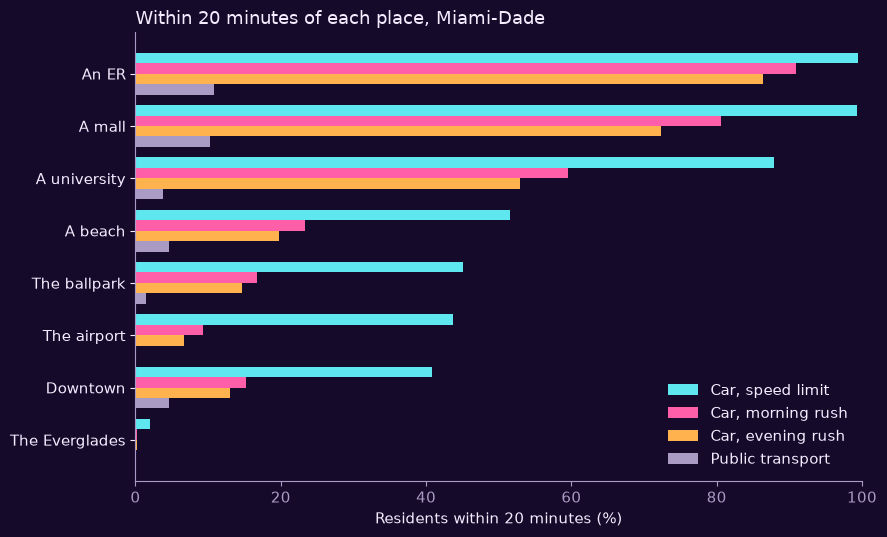

In [5]:
BG, INK, MUTED = '#160a2b', '#f4ecff', '#a99bc4'
COL = {'free': '#5ee7ef', 'am': '#ff5fa8', 'pm': '#ffb24d', 'pt': '#a99bc4'}
LABEL = {'free': 'Car, speed limit', 'am': 'Car, morning rush', 'pm': 'Car, evening rush', 'pt': 'Public transport'}
plt.rcParams.update({'figure.facecolor': BG, 'axes.facecolor': BG, 'savefig.facecolor': BG, 'text.color': INK,
                     'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': INK, 'axes.edgecolor': MUTED,
                     'font.size': 11})
order = table.sort_values('free').index
fig, ax = plt.subplots(figsize=(9, 5.5))
h = 0.2
for k, run in enumerate(['free', 'am', 'pm', 'pt']):
    ax.barh([i + (1.5 - k) * h for i in range(len(order))], table.loc[order, run] * 100, height=h, color=COL[run], label=LABEL[run])
ax.set_yticks(range(len(order)), order)
ax.set_xlim(0, 100); ax.set_xlabel('Residents within 20 minutes (%)')
ax.set_title('Within 20 minutes of each place, Miami-Dade', loc='left', color=INK)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

## How many of the eight

In [6]:
dist = pd.DataFrame({LABEL[run]: mb.groupby(counts(run)).residents.sum().reindex(range(9), fill_value=0) / total * 100 for run in ['free', 'am', 'pm', 'pt']})
dist.index.name = 'places within 20 minutes'
dist.round(1)

,"Car, speed limit","Car, morning rush","Car, evening rush",Public transport
places within 20 minutes,,,,
0,0.6,2.2,3.7,76.4
1,0.1,7.6,12.3,14.9
2,5.0,36.7,40.7,6.4
3,35.0,32.0,25.2,1.5
4,12.4,5.3,4.5,0.7
5,8.1,3.2,4.0,0.2
6,7.2,9.5,8.3,0.0
7,31.7,3.5,1.3,0.0
8,0.0,0.0,0.0,0.0


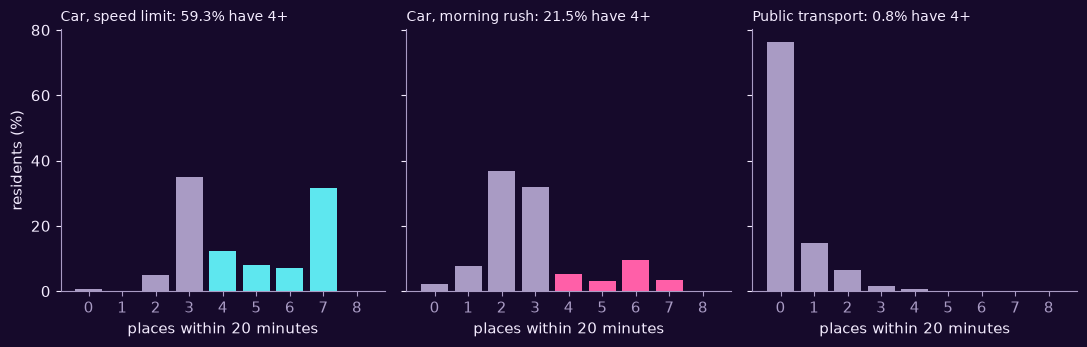

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for ax, run in zip(axes, ['free', 'am', 'pt']):
    d = dist[LABEL[run]]
    ax.bar(d.index, d.values, color=[COL[run] if i >= 4 else MUTED for i in d.index], width=0.8)
    ax.set_title(f"{LABEL[run]}: {d[d.index >= 4].sum():.1f}% have 4+", loc='left', fontsize=10, color=INK)
    ax.set_xticks(range(9)); ax.set_xlabel('places within 20 minutes')
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
axes[0].set_ylabel('residents (%)')
plt.tight_layout(); plt.show()

## Downtown by the minute

The share of residents who reach Government Center within each number of minutes. The gap between the lines is what
the rush hour costs.

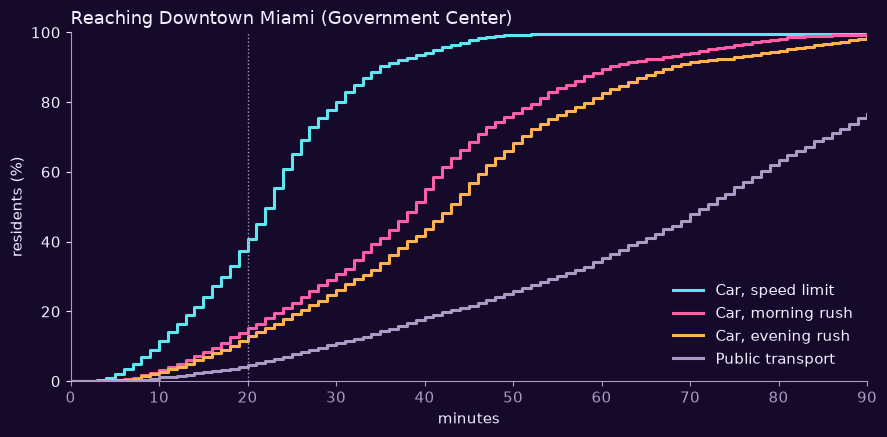

In [8]:
mins = list(range(0, 91, 1))
fig, ax = plt.subplots(figsize=(9, 4.5))
for run in ['free', 'am', 'pm', 'pt']:
    m = mb[f'{run}_cbd']
    ax.step(mins, [share(m <= t) * 100 for t in mins], where='post', color=COL[run], lw=2.2, label=LABEL[run])
ax.axvline(20, color=MUTED, lw=1, ls=':')
ax.set_xlim(0, 90); ax.set_ylim(0, 100)
ax.set_xlabel('minutes'); ax.set_ylabel('residents (%)')
ax.set_title('Reaching Downtown Miami (Government Center)', loc='left', color=INK)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

## Where it holds: Census places of 10,000 residents or more

In [9]:
pl = pd.read_csv(f'{DATA}/places_table.csv', dtype={'place_geoid': str})
big = pl[(pl.residents >= 10000) & pl.place_geoid.notna()]  # the row for blocks outside any Census place left out
print((big.share_half_free >= 0.5).sum(), 'of', len(big), 'places hold at the speed limit;',
      (big.share_half_am >= 0.5).sum(), 'in the morning rush hour;', (big.share_half_pt >= 0.5).sum(), 'by public transport')
big.sort_values(['share_half_am', 'places_within_20_free'], ascending=False)[['place_name', 'residents', 'share_half_free', 'share_half_am', 'share_half_pt', 'places_within_20_am']].head(10)

27 of 54 places hold at the speed limit; 3 in the morning rush hour; 0 by public transport


,place_name,residents,share_half_free,share_half_am,share_half_pt,places_within_20_am
0,Miami,442241,1.000,0.935,0.048,5.77
1,Brownsville,16583,1.000,0.861,0.018,5.01
29,North Miami Beach,43676,1.000,0.782,0.000,3.78
14,Coral Gables,49248,0.946,0.473,0.005,3.73
31,Ojus,19673,1.000,0.426,0.000,3.18
32,Aventura,40242,1.000,0.424,0.000,3.32
18,Golden Glades,32499,1.000,0.346,0.000,3.22
23,North Miami,60191,0.998,0.330,0.000,2.92
36,Sunny Isles Beach,22342,1.000,0.228,0.000,3.23
5,Miami Springs,13859,1.000,0.138,0.000,2.75


## Where it fails

In [10]:
big.sort_values(['share_half_free', 'places_within_20_free'])[['place_name', 'residents', 'share_half_free', 'places_within_20_free', 'mean_min_downtown_free']].head(10)

,place_name,residents,share_half_free,places_within_20_free,mean_min_downtown_free
68,Richmond West,35884,0.0,2.13,34.4
67,Cutler Bay,45425,0.0,2.15,34.2
66,Goulds,11446,0.0,2.37,33.8
65,Country Walk,16951,0.0,2.42,32.5
64,Princeton,39308,0.0,2.46,36.8
63,Three Lakes,16540,0.0,2.78,28.5
62,Leisure City,26324,0.0,2.89,40.8
61,South Miami Heights,36770,0.0,2.91,31.4
60,Palmetto Bay,24439,0.0,2.94,29.8
58,Naranja,13509,0.0,2.98,39.0


## Sources

OpenStreetMap (c) OpenStreetMap contributors, ODbL 1.0 (roads, beaches, malls; the minutes are a derived database
under the same licence). U.S. Census Bureau 2020 Census and TIGER/Line 2020 (public domain). CMS Hospital General
Information (public domain). TomTom Traffic Index 2025, Miami (cited figures). Miami-Dade Transit GTFS (fetched by
`scripts/get_gtfs.sh`, not redistributed).